# SchNet Baseline — 纯3D模型 (K-NN图 + 连续滤波卷积)

## 与 3D GAT 公平比较
| | SchNet (v2) | 3D GAT |
|---|---|---|
| 图构建 | K-NN (32 neighbors, 5A cutoff) | SMILES bonds + RBF |
| 节点特征 | 原子序数 (embedding) | 11d (SMILES 8d + BO 3d) |
| 边特征 | 20 RBF 距离编码 | 23d (bond 6d + RBF 16d + BO 1d) |
| 卷积 | CFConv (连续滤波) | GATConv (多头注意力) |
| 池化 | mean + sum | mean + max + metal-mean |
| 规模 | 384d x 5 层 | 384d x 5 层 |
| 数据划分 | ensemble_split.npz | ensemble_split.npz |

**目标**: 验证 GAT 注意力机制是否优于 SchNet 连续滤波，在相同规模和数据下。

In [1]:
# ===== Thread control (CPU limit 16 cores) =====
import os
os.environ['OMP_NUM_THREADS'] = '16'
os.environ['MKL_NUM_THREADS'] = '16'
os.environ['OPENBLAS_NUM_THREADS'] = '16'
os.environ['NUMEXPR_NUM_THREADS'] = '16'

import numpy as np, pandas as pd, time, gzip, os
import matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
import torch, torch.nn as nn, torch.optim as optim
import torch.nn.functional as F

torch.set_num_threads(16)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    torch.set_float32_matmul_precision('high')
    torch.backends.cuda.matmul.allow_tf32 = True
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm
print('Imports OK (CPU threads capped at 16)')

Device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti


Imports OK (CPU threads capped at 16)


In [2]:
df_y = pd.read_csv('./tmQM_y.csv', sep=';')
df_y = df_y.rename(columns={'HL_Gap': 'gap', 'HOMO_Energy': 'homo', 'LUMO_Energy': 'lumo', 'Dipole_M': 'dipole', 'Metal_q': 'metal_charge', 'Electronic_E': 'E_elec', 'Dispersion_E': 'E_disp', 'Polarizability': 'polarizability'})
targets = ['gap', 'homo', 'lumo', 'dipole', 'metal_charge', 'E_elec', 'E_disp', 'polarizability']
print(f'Loaded {len(df_y)} complexes')
df_y[targets].describe()


Loaded 108541 complexes


,gap,homo,lumo,dipole,metal_charge,E_elec,E_disp,polarizability
count,108541.000000,108541.000000,108541.000000,108541.000000,108541.000000,108541.000000,108541.000000,108541.000000
mean,0.108504,-0.197593,-0.089089,5.799450,0.162882,-2987.303526,-0.142228,397.124993
std,0.033575,0.053825,0.054517,3.927489,0.782914,1634.083288,0.070115,152.460083
min,0.001570,-0.442030,-0.371990,0.000000,-3.083370,-29008.530471,-1.122263,51.249960
25%,0.087780,-0.210770,-0.107840,2.977000,-0.235330,-3551.761675,-0.180599,285.598661
50%,0.109320,-0.186870,-0.079030,5.390300,0.249460,-2682.286991,-0.129635,372.962979
75%,0.129570,-0.168440,-0.056580,8.211900,0.661090,-1957.796717,-0.090185,483.132746
max,0.307420,0.066540,0.198190,106.464600,2.330130,-295.243567,-0.005205,3002.513834


In [3]:
import gzip
def atom_to_z(sym):
    tbl = {"H":1,"He":2,"Li":3,"Be":4,"B":5,"C":6,"N":7,"O":8,"F":9,"Ne":10,"Na":11,"Mg":12,"Al":13,"Si":14,"P":15,"S":16,"Cl":17,"Ar":18,"K":19,"Ca":20,"Sc":21,"Ti":22,"V":23,"Cr":24,"Mn":25,"Fe":26,"Co":27,"Ni":28,"Cu":29,"Zn":30,"Br":35,"Ru":44,"Rh":45,"Pd":46,"Ag":47,"Cd":48,"I":53,"Pt":78,"Au":79,"Hg":80,"Mo":42,"W":74,"Ir":77,"Os":76,"Re":75}
    return tbl.get(sym, 0)
def is_TM(z):
    return z in [21,22,23,24,25,26,27,28,29,30,39,40,41,42,43,44,45,46,47,48,72,73,74,75,76,77,78,79,80]
def parse_one(xyz_p, bo_p, start_idx=0):
    mols, labels, is_Fe = [], [], []
    with gzip.open(bo_p, "rt") as f: bo_lines = [l.strip() for l in f.readlines()]
    with gzip.open(xyz_p, "rt") as f: xyz_blocks = f.read().strip().split(chr(10))
    bo_blocks, cur = [], []
    for line in bo_lines:
        if line.startswith("CSD_code"):
            if cur: bo_blocks.append(cur); cur = []
        elif line: cur.append(line)
    if cur: bo_blocks.append(cur)
    i, mol_idx = 0, start_idx - 1
    while i < len(xyz_blocks):
        line = xyz_blocks[i].strip(); i += 1
        if not line: continue
        parts = line.split()
        if len(parts)==1 and parts[0].isdigit():
            n_atoms = int(parts[0])
            if i >= len(xyz_blocks): break
            i += 1
            atoms, coords = [], []
            for _ in range(n_atoms):
                if i >= len(xyz_blocks): break
                cline = xyz_blocks[i].strip(); i += 1
                cparts = cline.split()
                if len(cparts) >= 4:
                    try:
                        z = atom_to_z(cparts[0])
                        coords.append([float(x) for x in cparts[1:4]])
                        atoms.append(z)
                    except ValueError: continue
            mol_idx += 1
            if not any(is_TM(z) for z in atoms) or len(atoms) <= 1: continue
            bo_mat = None
            if mol_idx < len(bo_blocks):
                bo_mat = np.zeros((n_atoms, n_atoms), dtype=np.float32)
                for bline in bo_blocks[mol_idx]:
                    bparts = bline.split()
                    try: src_idx = int(bparts[0]) - 1
                    except ValueError: continue
                    j = 2
                    while j+1 < len(bparts):
                        try:
                            nbr = int(bparts[j]) - 1
                            bo_val = float(bparts[j+1])
                            if 0 <= src_idx < n_atoms and 0 <= nbr < n_atoms:
                                bo_mat[src_idx, nbr] = bo_val
                            j += 3
                        except (ValueError, IndexError): j += 1
            mols.append({"atoms": np.array(atoms), "coords": np.array(coords, dtype=np.float32), "bo": bo_mat, "csv_idx": mol_idx})
            labels.append(df_y.iloc[mol_idx][targets].astype(float).values)
            is_Fe.append(float(26 in atoms))
    return mols, labels, is_Fe
all_m, all_l, all_f = [], [], []
for part in [1,2,3]:
    m,l,f = parse_one(f"./tmQM_X{part}.xyz.gz", f"./tmQM_X{part}.BO.gz", start_idx=len(all_m))
    all_m.extend(m); all_l.extend(l); all_f.extend(f)
    print(f"  Part {part}: {len(m)} TM, Fe={int(sum(f))}")
fe_cmplx = all_m
y_fe = np.array(all_l, dtype=np.float32)
is_Fe_arr = np.array(all_f, dtype=np.float32)
print(f"Total: {len(fe_cmplx)} TM, {int(is_Fe_arr.sum())} Fe")


  Part 1: 28737 TM, Fe=1252


  Part 2: 35834 TM, Fe=4439


  Part 3: 37506 TM, Fe=0
Total: 102077 TM, 5691 Fe


In [4]:
N_RBF = 20
RBF_SIGMA = 0.1
CUTOFF = 5.0
K_NEIGHBORS = 32
rbf_centers = np.linspace(0.0, CUTOFF, N_RBF)

# ===== 30k subsample (与消融实验一致, 避免K-NN建图耗时过长) =====
N_SAMPLE = 30000
rng = np.random.RandomState(42)
perm = rng.permutation(len(fe_cmplx))[:N_SAMPLE]
fe_cmplx_sub = [fe_cmplx[i] for i in perm]
y_fe_sub = y_fe[perm]
print(f'Subsampled {N_SAMPLE:,} complexes (same as ablation experiments)')

def build_schnet_graph(atoms, coords):
    N = len(atoms)
    c = torch.tensor(coords, dtype=torch.float32)
    dist = torch.norm(c.unsqueeze(0) - c.unsqueeze(1), dim=2)
    k = min(K_NEIGHBORS + 1, N)
    _, nbr_idx = torch.topk(dist, k, dim=1, largest=False)
    # Vectorized RBF (avoid Python loop)
    edge_src = []; edge_dst = []
    for i in range(N):
        nbrs = nbr_idx[i, 1:].tolist()
        edge_src.extend([i]*len(nbrs)); edge_dst.extend(nbrs)
        edge_src.extend(nbrs); edge_dst.extend([i]*len(nbrs))
    if edge_src:
        d_src = c[edge_src]; d_dst = c[edge_dst]
        d_all = torch.norm(d_src - d_dst, dim=1).numpy()
        d_all = np.clip(d_all, 0, CUTOFF - 1e-6)
        rbf_all = np.exp(-(d_all[:, None] - rbf_centers[None, :])**2 / (2 * RBF_SIGMA**2))
        ei = torch.tensor([edge_src, edge_dst], dtype=torch.long)
        ea = torch.tensor(rbf_all, dtype=torch.float32)
    else:
        ei = torch.zeros(2, 0, dtype=torch.long)
        ea = torch.zeros(0, N_RBF)
    return {'z': torch.tensor(atoms, dtype=torch.long), 'pos': torch.tensor(coords, dtype=torch.float32), 'edge_index': ei, 'edge_rbf': ea}

print(f'Building SchNet graphs ({K_NEIGHBORS}-NN, {N_RBF} RBFs, vectorized)...')
graphs, y_vals, failed = [], [], 0
for m in tqdm(fe_cmplx_sub, desc='Building'):
    g = build_schnet_graph(m['atoms'], m['coords'])
    if g['edge_index'].shape[1] > 0:
        graphs.append(g); y_vals.append(df_y.iloc[m['csv_idx']][targets].astype(float).values)
    else: failed += 1
y_all = torch.tensor(y_vals, dtype=torch.float32)
mask = ~(torch.isnan(y_all).any(dim=1) | torch.isinf(y_all).any(dim=1))
graphs = [g for i,g in enumerate(graphs) if mask[i]]; y_all = y_all[mask]
print(f'Built {len(graphs):,} graphs ({failed} failed, {len(graphs)} after NaN)')
ec = [g['edge_index'].shape[1] for g in graphs]
print(f'Edges: min={min(ec)}, max={max(ec)}, mean={np.mean(ec):.0f}')

y_mean = y_all.mean(dim=0); y_std = y_all.std(dim=0).clamp(min=1e-8); y_norm = (y_all - y_mean) / y_std

# 30k subsample用自己的随机split (不与ensemble_split.npz共享索引)
idx = np.random.RandomState(42).permutation(len(graphs))
n_tr = int(len(graphs)*0.7); n_va = int(len(graphs)*0.15)
tr_idx = idx[:n_tr]; va_idx = idx[n_tr:n_tr+n_va]; te_idx = idx[n_tr+n_va:]
print(f'Train: {len(tr_idx):,} | Val: {len(va_idx):,} | Test: {len(te_idx):,}')
print('Note: SchNet uses 30k subsample (same scale as ablation). Full 95k would require multi-GPU/distributed training.')

Subsampled 30,000 complexes (same as ablation experiments)
Building SchNet graphs (32-NN, 20 RBFs, vectorized)...


Building:   0%|          | 0/30000 [00:00<?, ?it/s]

Building:   0%|          | 20/30000 [00:00<02:32, 196.49it/s]

Building:   0%|          | 40/30000 [00:00<03:07, 159.81it/s]

Building:   0%|          | 61/30000 [00:00<02:53, 172.99it/s]

...

Building: 100%|█████████▉| 29967/30000 [04:03<00:00, 122.50it/s]

Building: 100%|█████████▉| 29980/30000 [04:03<00:00, 118.57it/s]

Building: 100%|█████████▉| 29992/30000 [04:03<00:00, 106.47it/s]

Building: 100%|██████████| 30000/30000 [04:03<00:00, 123.26it/s]

Built 30,000 graphs (0 failed, 30000 after NaN)
Edges: min=144, max=18880, mean=4164
Train: 21,000 | Val: 4,500 | Test: 4,500
Note: SchNet uses 30k subsample (same scale as ablation). Full 95k would require multi-GPU/distributed training.


In [5]:
# ===== 模型: SchNet 384d x 5层 (与 GAT 相同规模) =====
HIDDEN = 384
N_LAYERS = 5
N_ATOM_TYPES = 85

from torch.amp import autocast, GradScaler

def collate_schnet(batch_list):
    z_list, pos_list, ei_list, rbf_list, batch_list2 = [], [], [], [], []
    offset = 0
    for i, g in enumerate(batch_list):
        n = g['z'].size(0)
        z_list.append(g['z']); pos_list.append(g['pos'])
        ei_list.append(g['edge_index'] + offset)
        rbf_list.append(g['edge_rbf'])
        batch_list2.append(torch.full((n,), i, dtype=torch.long))
        offset += n
    return {'z': torch.cat(z_list).to(device), 'pos': torch.cat(pos_list).to(device),
            'edge_index': torch.cat(ei_list, dim=1).to(device),
            'edge_rbf': torch.cat(rbf_list, dim=0).to(device),
            'batch': torch.cat(batch_list2).to(device), 'n_graphs': len(batch_list)}

class CFConv(nn.Module):
    def __init__(self, hidden, n_rbf):
        super().__init__()
        self.filter_net = nn.Sequential(nn.Linear(n_rbf, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
    def forward(self, h, ei, rbf):
        src, dst = ei[0], ei[1]; N = h.size(0)
        W = self.filter_net(rbf)
        msg = h[src] * W
        out = torch.zeros(N, h.size(1), device=h.device, dtype=h.dtype)
        out.scatter_add_(0, dst.unsqueeze(-1).expand_as(msg), msg)
        return out

class SchNet(nn.Module):
    def __init__(self, hidden=HIDDEN, n_layers=N_LAYERS, n_rbf=N_RBF):
        super().__init__()
        self.embed = nn.Embedding(N_ATOM_TYPES, hidden, padding_idx=0)
        self.interactions = nn.ModuleList([CFConv(hidden, n_rbf) for _ in range(n_layers)])
        self.atomwise = nn.ModuleList([nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden)) for _ in range(n_layers)])
        self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
        self.drop = nn.Dropout(0.10)
        # 直接预测 8 个标量性质 (无 charge head)
        self.readout = nn.Sequential(
            nn.Linear(hidden*2, hidden), nn.SiLU(), nn.Dropout(0.10),
            nn.Linear(hidden, hidden//2), nn.SiLU(), nn.Dropout(0.10),
            nn.Linear(hidden//2, 8))

    def forward(self, batched_dict):
        z, ei, rbf = batched_dict['z'], batched_dict['edge_index'], batched_dict['edge_rbf']
        batch = batched_dict['batch']; n_graphs = batched_dict['n_graphs']
        h = self.embed(z)
        for inter, atom, norm in zip(self.interactions, self.atomwise, self.norms):
            h = norm(h + atom(inter(h, ei, rbf))); h = self.drop(h)
        # mean + sum pooling
        mean_h = torch.zeros(n_graphs, h.size(1), device=h.device, dtype=h.dtype)
        mean_h.scatter_add_(0, batch.unsqueeze(-1).expand_as(h), h)
        cnt = torch.zeros(n_graphs, device=h.device, dtype=h.dtype)
        cnt.scatter_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
        mean_h = mean_h / cnt.clamp(min=1).unsqueeze(-1)
        sum_h = mean_h * cnt.unsqueeze(-1)
        return self.readout(torch.cat([mean_h, sum_h], dim=1))

m = SchNet().to(device)
print(f'Params: {sum(p.numel() for p in m.parameters()):,}')
# 快速测试
g0 = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in graphs[0].items()}
bg = collate_schnet([g0, g0])
out = m(bg)
print(f'Output shape: {list(out.shape)} (expect [2, 8])')
print(f'HIDDEN={HIDDEN} N_LAYERS={N_LAYERS} N_RBF={N_RBF}')

Params: 2,665,160


Output shape: [2, 8] (expect [2, 8])
HIDDEN=384 N_LAYERS=5 N_RBF=20


In [6]:
# ===== Training: CosineWarmRestarts + AMP + CPU常驻图 =====
model = SchNet().to(device)
opt = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
sched = optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=50, T_mult=2, eta_min=1e-6)
crit = nn.MSELoss()
scaler = GradScaler('cuda')
y_norm_gpu = y_norm.to(device)

print(f'{len(graphs):,} graphs stay on CPU (K-NN={K_NEIGHBORS} edges too large for GPU preload)')

def fast_collate(indices):
    bg_list = [graphs[i] for i in indices]
    z_list, pos_list, ei_list, rbf_list, batch_list2 = [], [], [], [], []
    offset = 0
    for k, g in enumerate(bg_list):
        n = g['z'].size(0)
        z_list.append(g['z']); pos_list.append(g['pos'])
        ei_list.append(g['edge_index'] + offset)
        rbf_list.append(g['edge_rbf'])
        batch_list2.append(torch.full((n,), k, dtype=torch.long))
        offset += n
    return {'z': torch.cat(z_list).to(device), 'pos': torch.cat(pos_list).to(device),
            'edge_index': torch.cat(ei_list, dim=1).to(device),
            'edge_rbf': torch.cat(rbf_list, dim=0).to(device),
            'batch': torch.cat(batch_list2).to(device), 'n_graphs': len(bg_list)}

epochs, bs = 200, 64
early_stop_patience = 40
hist = {'tr': [], 'va': []}
best_va = float('inf'); best_state = None; patience_counter = 0
print(f'Training {epochs} epochs (batch={bs}) on {device}...')
print(f'Model: SchNet {N_LAYERS}L x {HIDDEN}d | AMP FP16 | CosineWarmRestarts')
print(f'Params: {sum(p.numel() for p in model.parameters()):,}\n')

for ep in range(epochs):
    model.train(); perm = torch.randperm(len(tr_idx)); tr_loss = 0; n_batches = 0
    for s in range(0, len(tr_idx), bs):
        bidx = tr_idx[perm[s:s+bs]].tolist()
        batched = fast_collate(bidx); by = y_norm_gpu[bidx]
        opt.zero_grad()
        with autocast('cuda'):
            loss = crit(model(batched), by)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        tr_loss += loss.item(); n_batches += 1
    model.eval()
    with torch.no_grad():
        va_preds = []
        for s in range(0, len(va_idx), bs):
            bidx = va_idx[s:s+bs].tolist()
            batched = fast_collate(bidx)
            with autocast('cuda'):
                va_preds.append(model(batched).float())
        vp = torch.cat(va_preds, dim=0)
        va_loss = crit(vp, y_norm_gpu[va_idx])
    sched.step(ep)  # epoch-based (not va_loss, which goes NaN for SchNet)
    hist['tr'].append(tr_loss / max(1, n_batches))
    hist['va'].append(va_loss.item())
    if va_loss < best_va:
        best_va = va_loss; best_state = {k: v.clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
    if patience_counter >= early_stop_patience:
        print(f'Early stop at epoch {ep+1}'); break
    if (ep+1) % 20 == 0:
        vp_orig = vp.cpu() * y_std + y_mean
        vt_orig = y_all[va_idx]
        mae_per = torch.mean(torch.abs(vp_orig - vt_orig), dim=0)
        avg_mae = mae_per.mean().item()
        print(f'Epoch {ep+1:3d} | TrLoss {hist["tr"][-1]:.4f} | VaLoss {va_loss.item():.4f} | AvgMAE {avg_mae:.4f} | Pat {patience_counter}')

print(f'\nDone. Best val loss: {best_va:.4f}')
model.load_state_dict(best_state); model.eval()
torch.save(best_state, 'schnet_best.pt')
print('Saved to schnet_best.pt')

30,000 graphs stay on CPU (K-NN=32 edges too large for GPU preload)
Training 200 epochs (batch=64) on cuda...
Model: SchNet 5L x 384d | AMP FP16 | CosineWarmRestarts
Params: 2,665,160



Epoch  20 | TrLoss 1.0017 | VaLoss 1.0056 | AvgMAE 148.1774 | Pat 11


Epoch  40 | TrLoss 1.0014 | VaLoss 1.0056 | AvgMAE 148.2024 | Pat 14


Epoch  60 | TrLoss 1.0036 | VaLoss 1.0056 | AvgMAE 147.8550 | Pat 34


Early stop at epoch 66

Done. Best val loss: 1.0055
Saved to schnet_best.pt



SCHNET TEST SET RESULTS (same split as 3D GAT)
Property                  MAE       R2
----------------------------------------
gap                    0.0253  -0.0000
homo                   0.0382  -0.0013
lumo                   0.0393  -0.0010
dipole                 2.9613  -0.0003
metal_charge           0.5786  -0.0001
E_elec              1061.5311  -0.0000
E_disp                 0.0555  -0.0008
polarizability       119.8603  -0.0006

SchNet Mean R2: -0.0005
Saved schnet_results.json


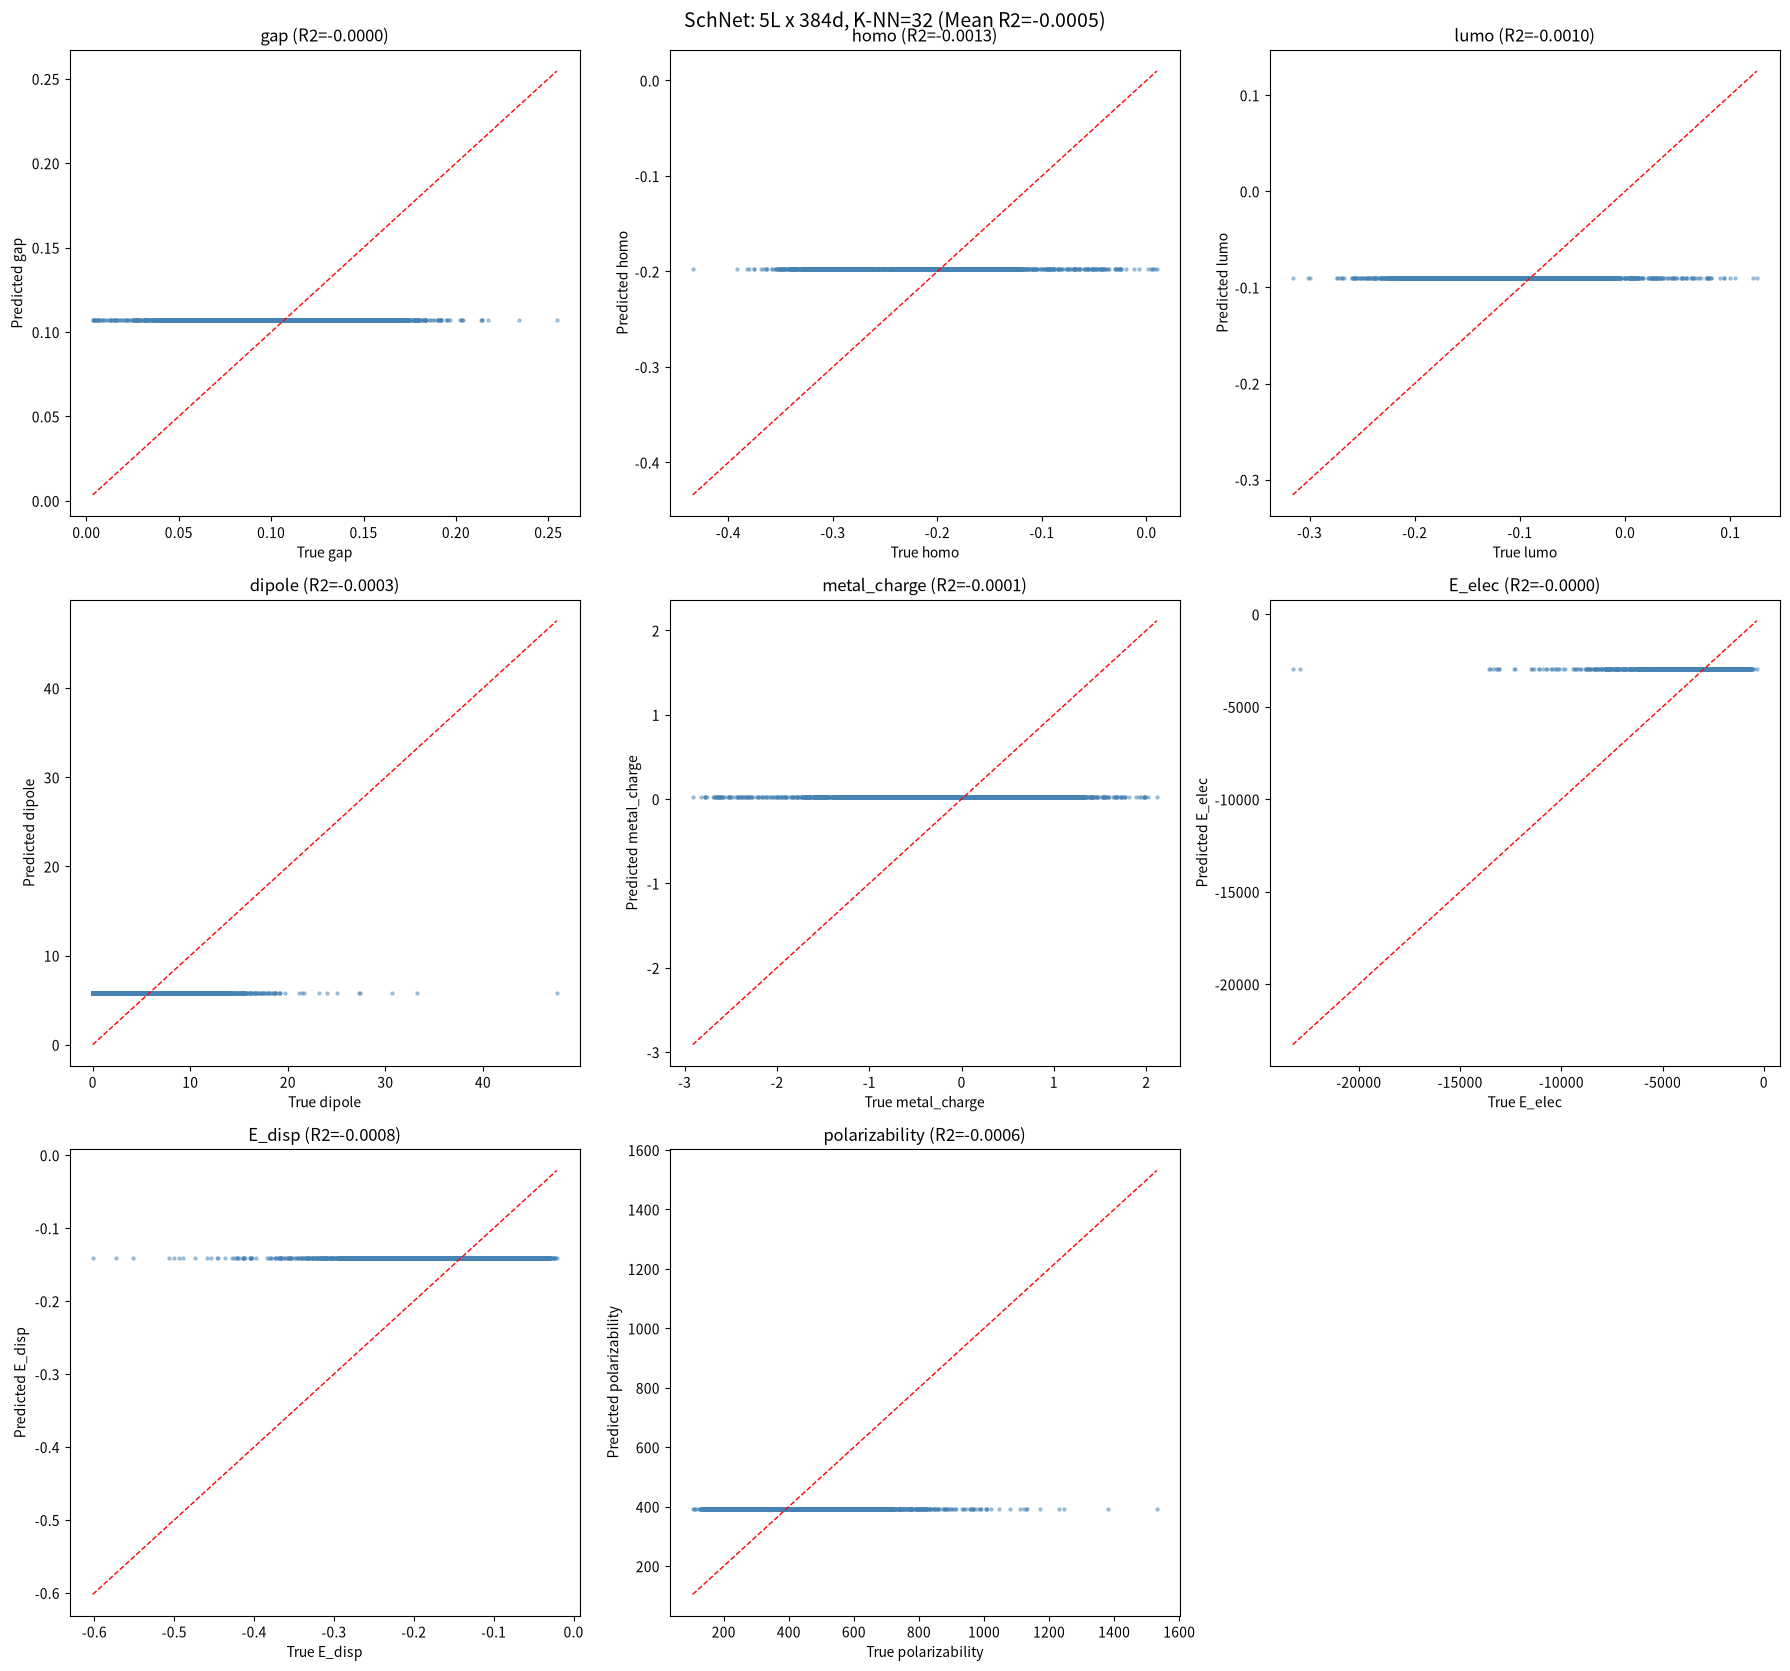

Saved figure_schnet.png


In [7]:
# ===== Test Set Evaluation (CPU图 + batch传输) =====
model.eval()
bs_eval = 64
with torch.no_grad():
    te_preds = []
    for s in range(0, len(te_idx), bs_eval):
        bidx = te_idx[s:s+bs_eval].tolist()
        batched = fast_collate(bidx)
        with autocast('cuda'):
            te_preds.append(model(batched).float().cpu())
    tp = torch.cat(te_preds, dim=0)
    tp_orig = tp * y_std + y_mean
    tt_orig = y_all[te_idx]

print(f'\n{"="*60}')
print('SCHNET TEST SET RESULTS (same split as 3D GAT)')
print(f'{"="*60}')
print(f'{"Property":18s} {"MAE":>10s} {"R2":>8s}')
print('-' * 40)
results = []
for i, prop in enumerate(targets):
    yt, yp = tt_orig[:, i].numpy(), tp_orig[:, i].numpy()
    mae = mean_absolute_error(yt, yp); r2 = r2_score(yt, yp)
    print(f'{prop:18s} {mae:10.4f} {r2:8.4f}')
    results.append({'Property': prop, 'MAE': float(mae), 'R2': float(r2)})

mean_r2 = np.mean([r['R2'] for r in results])
print(f'\nSchNet Mean R2: {mean_r2:.4f}')

import json
with open('schnet_results.json', 'w') as f:
    json.dump({'results': results, 'mean_r2': mean_r2}, f, indent=2)
print('Saved schnet_results.json')

# Parity plots
fig, axes = plt.subplots(3, 3, figsize=(18, 17))
axes = axes.flatten()
for ax, i, prop in zip(axes, range(len(targets)), targets):
    yt, yp = tt_orig[:, i].numpy(), tp_orig[:, i].numpy()
    ax.scatter(yt, yp, alpha=0.4, s=5, c='steelblue')
    lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
    ax.plot(lims, lims, 'r--', lw=1)
    ax.set_xlabel(f'True {prop}'); ax.set_ylabel(f'Predicted {prop}')
    ax.set_title(f'{prop} (R2={r2_score(yt, yp):.4f})')
axes[-1].set_visible(False)
plt.suptitle(f'SchNet: {N_LAYERS}L x {HIDDEN}d, K-NN={K_NEIGHBORS} (Mean R2={mean_r2:.4f})', fontsize=14)
plt.tight_layout()
plt.savefig('figure_schnet.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved figure_schnet.png')